# Pregunta 1 MRI de rodilla

## Instrucciones de ejecución

1. Descargar **data_pregunta_1_mri.zip** desde [Google Drive](https://drive.google.com/file/d/1Uznugg_frBnnSt75cd6bvPTquaZrFn1q/view?usp=sharing).
2. Extraer el archivo ZIP.
3. En la siguiente celda, asignar a **`DATA_ROOT`** la ruta de la carpeta extraída
   **`data_pregunta_1_mri`**. Usar la carpeta que contiene directamente
   `train.csv`, `train_series.csv`, `seleccion_estudios.csv` y `train_series/`.
4. Ejecutar todas las celdas del notebook en orden.

Ejemplo de configuración después de extraer:

```python
DATA_ROOT = Path("ruta/a/data_pregunta_1_mri")
```

En Windows, otra PC o Google Colab, usar la ruta donde se encuentre esa carpeta
extraída y accesible para el notebook.

El notebook instala los paquetes ausentes, conserva una instalación existente de
PyTorch/torchvision y descarga los pesos públicos ImageNet de ResNet-50 desde
PyTorch. Se necesita Internet para esas descargas iniciales. Todo el código y los
parámetros están incluidos; no se necesitan archivos de experimentos anteriores.
Se registra el entorno utilizado; equipos y versiones diferentes pueden producir
resultados distintos aunque se mantenga la semilla.

Cada ejecución crea una carpeta nueva dentro de `resultados_mri/`, en el directorio
de trabajo del notebook. Allí se generan etiquetas, particiones, cachés a partir
de DICOM, ocho entrenamientos, predicciones, métricas, figuras y Grad-CAM.
La carpeta de entrada se utiliza exclusivamente para lectura.

La ejecución completa usa 600 estudios: 434 de entrenamiento, 108 de validación
débil y 58 expertos. Compara CNN propia/ResNet-50 × BCE/focal × dos tratamientos
del ruido, hasta 50 épocas con parada temprana. Usa GPU si está disponible y CPU
en caso contrario; CPU será considerablemente más lento.

`SMOKE_TEST=True` permite comprobar el flujo desde cero con 8 estudios de
entrenamiento, 8 de validación, los 58 expertos y una época por variante.
Este modo produce resultados de prueba técnica, no resultados científicos finales.
El valor predeterminado es `False`. Los resultados guardados en las celdas indican
qué modo se ejecutó; no se presenta una prueba técnica como entrenamiento completo.

**Salidas incluidas:** corresponden a la verificación desde cero con SMOKE_TEST=True: 74 estudios, una época por variante. Al ejecutar el valor predeterminado False, se usan los 600 estudios y hasta 50 épocas. La verificación se realizó en Linux con GPU; no se ejecutó directamente en el servicio de Colab.


In [ ]:
from pathlib import Path
from types import SimpleNamespace
from datetime import datetime, timezone
import importlib.util
import os
import subprocess
import shutil
import sys
import uuid
import copy
import json

# This is the only input path to change on another PC or Colab.
DEFAULT_DATA_ROOT = 'E:/Kaggle/data_pregunta_1_mri' if os.name == 'nt' else '/content/data_pregunta_1_mri'
DATA_ROOT = Path(os.environ.get('MRI_DATA_ROOT', DEFAULT_DATA_ROOT)).expanduser()
SMOKE_TEST = os.environ.get('MRI_SMOKE_TEST', '0') == '1'

if sys.version_info < (3, 11):
    raise RuntimeError('Use Python 3.11 or newer.')
if not DATA_ROOT.is_dir():
    raise FileNotFoundError(f'Set DATA_ROOT to the selected Kaggle data folder: {DATA_ROOT}')
for required in ('train.csv', 'train_series.csv', 'seleccion_estudios.csv', 'train_series'):
    if not (DATA_ROOT / required).exists():
        raise FileNotFoundError(f'Missing dataset component: {DATA_ROOT / required}')

packages = {
    'numpy': 'numpy>=1.26', 'pandas': 'pandas>=2.0', 'matplotlib': 'matplotlib>=3.8',
    'sklearn': 'scikit-learn>=1.5', 'torch': 'torch>=2.4', 'torchvision': 'torchvision>=0.19',
    'pydicom': 'pydicom>=3.0', 'pylibjpeg': 'pylibjpeg>=2.0',
    'libjpeg': 'pylibjpeg-libjpeg>=2.1', 'openjpeg': 'pylibjpeg-openjpeg>=2.3',
    'PIL': 'Pillow>=10.0',
}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
def install_dependencies(requirements):
    """Install into the active kernel, including uv environments without pip."""
    def run_installer(command):
        result = subprocess.run(command, capture_output=True, text=True, errors='replace')
        if result.returncode:
            details = '\n'.join(part for part in (result.stdout, result.stderr) if part)
            raise RuntimeError(
                f'Dependency installation failed for {sys.executable}.\n'
                f'Command: {command!r}\n{details}'
            )
        if result.stdout.strip():
            print(result.stdout.strip())
        if result.stderr.strip():
            print(result.stderr.strip())

    if importlib.util.find_spec('pip') is not None:
        command = [sys.executable, '-m', 'pip', 'install', *requirements]
    elif shutil.which('uv'):
        command = [shutil.which('uv'), 'pip', 'install', '--python', sys.executable, *requirements]
    else:
        run_installer([sys.executable, '-m', 'ensurepip', '--upgrade'])
        command = [sys.executable, '-m', 'pip', 'install', *requirements]
    run_installer(command)
    importlib.invalidate_caches()


if missing:
    install_dependencies(missing)

import pandas as pd
from IPython.display import Image, display

run_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid.uuid4().hex[:8]
OUTPUT_ROOT = Path(os.environ.get('MRI_OUTPUT_ROOT', str(Path.cwd() / 'resultados_mri' / run_id)))
if OUTPUT_ROOT.resolve().is_relative_to(DATA_ROOT.resolve()):
    raise ValueError('The output directory must be outside DATA_ROOT.')
if OUTPUT_ROOT.exists():
    raise FileExistsError('Each execution needs a new output directory.')
OUTPUT_ROOT.mkdir(parents=True)
WEIGHTS_ROOT = OUTPUT_ROOT / 'weights'
WEIGHTS_ROOT.mkdir()
ACTIVE_ROOT = OUTPUT_ROOT
print('Mode:', 'TECHNICAL SMOKE TEST' if SMOKE_TEST else 'FULL TRAINING')
print('Data:', DATA_ROOT)
print('New output:', OUTPUT_ROOT)

In [2]:
"""Small, explicit artifact readers and writers."""

from __future__ import annotations

import csv
import hashlib
import json
import math
from pathlib import Path
from typing import Any


def clean_json(value: Any) -> Any:
    """Represent undefined numeric metrics as null, never invalid JSON NaN."""
    if isinstance(value, dict):
        return {str(key): clean_json(item) for key, item in value.items()}
    if isinstance(value, list | tuple):
        return [clean_json(item) for item in value]
    if isinstance(value, Path):
        return str(value)
    if hasattr(value, "tolist"):
        return clean_json(value.tolist())
    if isinstance(value, float) and not math.isfinite(value):
        return None
    return value


def write_json(path: Path, value: Any) -> None:
    """Atomically persist structured results."""
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(clean_json(value), indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8")
    temporary.replace(path)


def read_json(path: Path) -> Any:
    """Read a UTF-8 JSON artifact."""
    return json.loads(path.read_text(encoding="utf-8"))


def write_csv(path: Path, rows: list[dict], fields: list[str] | None = None) -> None:
    """Write stable tabular artifacts, including empty files with headers."""
    fields = fields or list(dict.fromkeys(key for row in rows for key in row))
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", encoding="utf-8", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=fields)
        writer.writeheader()
        writer.writerows(rows)


def read_csv(path: Path) -> list[dict[str, str]]:
    """Read metadata without interpreting identifiers as floating-point values."""
    with path.open(encoding="utf-8-sig", newline="") as stream:
        return list(csv.DictReader(stream))


def fingerprint(value: Any) -> str:
    """Hash configuration and split identities for resume compatibility."""
    encoded = json.dumps(clean_json(value), sort_keys=True, ensure_ascii=False).encode()
    return hashlib.sha256(encoded).hexdigest()


def file_sha256(path: Path) -> str:
    """Hash an artifact without loading it into memory."""
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(4 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


In [3]:
"""Publication-oriented figures generated only from recorded experiments."""

from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np

COLORS = ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]


def save_figure(figure, path: Path) -> None:
    """Save a legible raster figure and release its memory."""
    path.parent.mkdir(parents=True, exist_ok=True)
    figure.tight_layout()
    figure.savefig(path, dpi=200, bbox_inches="tight")
    plt.close(figure)


def history_plot(rows: list[dict], path: Path) -> None:
    """Plot training and validation losses on the same axes."""
    figure, axis = plt.subplots(figsize=(7, 4))
    for key, label, style, color in (
        ("train_loss", "Entrenamiento", "-", COLORS[0]),
        ("val_loss", "Validación", "--", COLORS[1]),
    ):
        axis.plot([row["epoch"] for row in rows], [row[key] for row in rows], style, label=label, color=color)
    axis.set(xlabel="Época", ylabel="Pérdida", title="Evolución del entrenamiento")
    axis.legend()
    save_figure(figure, path)


def bar_plot(names: list[str], values: list[float], path: Path, title: str, xlabel: str) -> None:
    """Produce sorted horizontal comparisons with a zero baseline."""
    order = np.argsort(values)
    figure, axis = plt.subplots(figsize=(8, max(3, len(names) * 0.3)))
    axis.barh([names[index] for index in order], [values[index] for index in order], color=COLORS[0])
    axis.set(xlim=(0, None), title=title, xlabel=xlabel)
    save_figure(figure, path)


def cam_plot(image: np.ndarray, heatmap: np.ndarray, path: Path, title: str) -> None:
    """Show the input and activation overlay side by side."""
    figure, axes = plt.subplots(1, 2, figsize=(8, 4))
    for axis in axes:
        axis.imshow(image, cmap="gray" if image.ndim == 2 else None)
        axis.axis("off")
    axes[0].set_title("Imagen")
    axes[1].imshow(heatmap, cmap="magma", alpha=0.5)
    axes[1].set_title(title)
    save_figure(figure, path)


In [4]:
"""Metrics with explicit missing-label and missing-class handling."""

from __future__ import annotations

import numpy as np
from sklearn.metrics import precision_recall_fscore_support, roc_auc_score


def multilabel_metrics(targets: np.ndarray, probabilities: np.ndarray, labels: list[str], threshold: float) -> dict:
    """Compute macro AUC only when every required target has two classes."""
    targets, probabilities = np.asarray(targets), np.asarray(probabilities)
    if targets.shape != probabilities.shape or targets.ndim != 2 or targets.shape[1] != len(labels):
        raise ValueError("Expected matching [studies, labels] arrays.")
    if not np.isfinite(probabilities).all() or ((probabilities < 0) | (probabilities > 1)).any():
        raise ValueError("Probabilities must be finite and between zero and one.")
    results = []
    for index, name in enumerate(labels):
        valid = np.isfinite(targets[:, index])
        truth = targets[valid, index]
        scores = probabilities[valid, index]
        if not np.isin(truth, (0, 1)).all():
            raise ValueError("Observed labels must be binary.")
        precision, recall, f1, _ = (
            precision_recall_fscore_support(truth, scores >= threshold, average="binary", zero_division=0)
            if len(truth)
            else (None, None, None, None)
        )
        auc = float(roc_auc_score(truth, scores)) if len(np.unique(truth)) == 2 else None
        results.append(
            {
                "label": name,
                "support": len(truth),
                "positives": int(truth.sum()),
                "auc": auc,
                "precision": precision,
                "recall": recall,
                "f1": f1,
            }
        )
    defined = [row["auc"] for row in results if row["auc"] is not None]
    return {
        "threshold": threshold,
        "per_label": results,
        "auc_labels_defined": len(defined),
        "macro_auc": float(np.mean(defined)) if len(defined) == len(labels) else None,
        "partial_macro_auc": float(np.mean(defined)) if defined else None,
        "macro_f1": float(np.mean([row["f1"] for row in results if row["f1"] is not None]))
        if any(row["f1"] is not None for row in results)
        else None,
    }


def binary_counts(target: np.ndarray, probability: np.ndarray, threshold: float = 0.5) -> dict:
    """Count pixel confusion after masking invalid ground truth (-1)."""
    valid = np.isin(target, (0, 1))
    truth = target[valid].astype(bool)
    prediction = probability[valid] >= threshold
    return {
        "tp": int((truth & prediction).sum()),
        "fp": int((~truth & prediction).sum()),
        "fn": int((truth & ~prediction).sum()),
        "tn": int((~truth & ~prediction).sum()),
    }


def metrics_from_counts(counts: dict) -> dict:
    """Return undefined ratios as null rather than assigning perfect scores."""
    tp, fp, fn, tn = (counts[key] for key in ("tp", "fp", "fn", "tn"))

    def ratio(numerator, denominator):
        return numerator / denominator if denominator else None

    return {
        **counts,
        "valid_pixels": tp + fp + fn + tn,
        "iou": ratio(tp, tp + fp + fn),
        "precision": ratio(tp, tp + fp),
        "recall": ratio(tp, tp + fn),
        "f1": ratio(2 * tp, 2 * tp + fp + fn),
        "omission": ratio(fn, tp + fn),
        "commission": ratio(fp, tp + fp),
    }


In [5]:
"""Supervised training with explicit device selection and resumable state."""

from __future__ import annotations

import os
import random
from pathlib import Path

import numpy as np
import torch
from torch.utils.data import DataLoader



def seed_everything(seed: int) -> None:
    """Seed Python, NumPy and PyTorch before creating models or loaders."""
    os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True, warn_only=True)


def resolve_device(requested: str) -> torch.device:
    """Fail on an unavailable requested GPU instead of silently training on CPU."""
    if requested == "auto":
        requested = "cuda" if torch.cuda.is_available() else "cpu"
    if requested == "cuda" and not torch.cuda.is_available():
        raise RuntimeError("CUDA is unavailable. Check Docker GPU access, or explicitly select --device cpu.")
    return torch.device(requested)


def seed_worker(worker_id: int) -> None:
    """Seed each data-loading process from its reproducible PyTorch seed."""
    worker_seed = torch.initial_seed() % (2**32)
    random.seed(worker_seed)
    np.random.seed(worker_seed)


def make_loader(dataset, batch_size: int, config: dict, shuffle: bool = False) -> DataLoader:
    """Build bounded loaders; new workers on each epoch allow exact seed restoration."""
    generator = torch.Generator().manual_seed(config["seed"])
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=config["workers"],
        pin_memory=config["device"] != "cpu",
        persistent_workers=False,
        worker_init_fn=seed_worker,
        generator=generator,
    )


def _rng_state() -> dict:
    numpy_state = np.random.get_state()
    return {
        "python": random.getstate(),
        "numpy": [numpy_state[0], numpy_state[1].tolist(), numpy_state[2], numpy_state[3], numpy_state[4]],
        "torch": torch.get_rng_state(),
        "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else [],
    }


def _restore_rng(state: dict) -> None:
    random.setstate(state["python"])
    value = state["numpy"]
    np.random.set_state((value[0], np.array(value[1], dtype=np.uint32), value[2], value[3], value[4]))
    torch.set_rng_state(state["torch"])
    if state["cuda"] and torch.cuda.is_available():
        torch.cuda.set_rng_state_all(state["cuda"])


def _save_checkpoint(path: Path, state: dict) -> None:
    temporary = path.with_suffix(".tmp")
    torch.save(state, temporary)
    temporary.replace(path)


def fit(
    model,
    train_loader,
    val_loader,
    loss_function,
    config: dict,
    run_dir: Path,
    data_identity: str,
    resume: bool = False,
) -> Path:
    """Train until validation loss stops improving; never select using final test data."""
    run_dir.mkdir(parents=True, exist_ok=True)
    signature = fingerprint({"training": config, "data_identity": data_identity})
    metadata_path = run_dir / "run.json"
    if metadata_path.exists() and read_json(metadata_path)["signature"] != signature:
        raise ValueError("Existing run has different configuration or partitions; use a new output directory.")
    if (run_dir / "complete.json").exists():
        if not resume:
            raise FileExistsError("Run already complete. Use --resume to reuse its recorded checkpoint.")
        return run_dir / "best.pt"
    if (run_dir / "last.pt").exists() and not resume:
        raise FileExistsError("Interrupted run found. Use --resume or choose a new output directory.")
    device = resolve_device(config["device"])
    model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=config["learning_rate"], weight_decay=config["weight_decay"])
    amp_enabled = config["amp"] and device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=amp_enabled)
    start_epoch, best_loss, stale, history = 0, float("inf"), 0, []
    if resume and (run_dir / "last.pt").exists():
        state = torch.load(run_dir / "last.pt", map_location="cpu", weights_only=True)
        model.load_state_dict(state["model"])
        optimizer.load_state_dict(state["optimizer"])
        scaler.load_state_dict(state["scaler"])
        start_epoch, best_loss, stale, history = state["epoch"], state["best_loss"], state["stale"], state["history"]
        _restore_rng(state["rng"])
        train_loader.generator.set_state(state["train_generator"])
        val_loader.generator.set_state(state["val_generator"])
    write_json(
        metadata_path,
        {
            "signature": signature,
            "configuration": config,
            "data_identity": data_identity,
            "torch_version": torch.__version__,
            "device": str(device),
            "status": "running",
            "model_selection": "minimum validation loss",
        },
    )
    for epoch in range(start_epoch, config["epochs"]):
        if stale >= config["patience"]:
            break
        averages = []
        for training, loader in ((True, train_loader), (False, val_loader)):
            model.train(training)
            numerator, denominator = 0.0, 0
            for image, target, weight in loader:
                image, target, weight = (value.to(device, non_blocking=True) for value in (image, target, weight))
                optimizer.zero_grad(set_to_none=True)
                with torch.set_grad_enabled(training), torch.amp.autocast("cuda", enabled=amp_enabled):
                    loss = loss_function(model(image), target, weight)
                if not torch.isfinite(loss):
                    raise FloatingPointError(f"Non-finite loss at epoch {epoch + 1}.")
                if training:
                    scaler.scale(loss).backward()
                    scaler.unscale_(optimizer)
                    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    scaler.step(optimizer)
                    scaler.update()
                numerator += loss.item() * image.shape[0]
                denominator += image.shape[0]
            if not denominator:
                raise ValueError("Training and validation loaders must both contain examples.")
            averages.append(numerator / denominator)
        improved = averages[1] < best_loss
        best_loss = min(best_loss, averages[1])
        stale = 0 if improved else stale + 1
        history.append({"epoch": epoch + 1, "train_loss": averages[0], "val_loss": averages[1]})
        state = {
            "epoch": epoch + 1,
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "scaler": scaler.state_dict(),
            "best_loss": best_loss,
            "stale": stale,
            "history": history,
            "rng": _rng_state(),
            "train_generator": train_loader.generator.get_state(),
            "val_generator": val_loader.generator.get_state(),
        }
        _save_checkpoint(run_dir / "last.pt", state)
        if improved:
            _save_checkpoint(run_dir / "best.pt", state)
        write_csv(run_dir / "history.csv", history)
        print(f"{run_dir.name}: epoch {epoch + 1}, validation loss {averages[1]:.5f}", flush=True)
    history_plot(history, run_dir / "loss.png")
    write_json(run_dir / "complete.json", {"epochs_executed": len(history), "best_val_loss": best_loss})
    write_json(
        metadata_path,
        {
            **read_json(metadata_path),
            "status": "complete",
            "epochs_executed": len(history),
            "best_val_loss": best_loss,
        },
    )
    return run_dir / "best.pt"


def restore_model(model, checkpoint: Path, device: torch.device):
    """Load a project's own state dictionary for final evaluation."""
    state = torch.load(checkpoint, map_location="cpu", weights_only=True)
    model.load_state_dict(state["model"])
    return model.to(device).eval()


In [6]:
"""Grad-CAM computed from differentiable scores before postprocessing."""

from __future__ import annotations

import torch
from torch import nn
from torch.nn import functional as F


class GradCAM:
    """Capture feature gradients while avoiding full backward-hook/in-place conflicts."""

    def __init__(self, layer: nn.Module):
        self.features = None
        self.gradients = None
        self.handle = layer.register_forward_hook(self._capture)

    def _capture(self, module, inputs, output):
        self.features = output
        self.gradients = None
        output.register_hook(self._save_gradients)

    def _save_gradients(self, gradient):
        self.gradients = gradient

    def maps(self, score: torch.Tensor, size: tuple[int, int]) -> torch.Tensor:
        """Backpropagate a scalar score and normalize each captured image map."""
        score.backward()
        if self.gradients is None:
            raise RuntimeError("The selected score does not depend on the captured layer.")
        weights = self.gradients.mean(dim=(-2, -1), keepdim=True)
        maps = (weights * self.features).sum(dim=1, keepdim=True).relu()
        maps = F.interpolate(maps, size=size, mode="bilinear", align_corners=False).squeeze(1)
        minimum = maps.flatten(1).amin(1)[:, None, None]
        maximum = maps.flatten(1).amax(1)[:, None, None]
        return ((maps - minimum) / (maximum - minimum).clamp_min(1e-8)).detach()

    def close(self):
        """Remove hooks after the explanation to release feature references."""
        self.handle.remove()
        self.features = self.gradients = None


## 1 Extracción de etiquetas débiles
Reglas multilingües con negaciones, incertidumbre y abstenciones. La confianza es un peso heurístico, no una probabilidad calibrada. El acuerdo se informa junto a la cobertura para evitar ocultar abstenciones.

In [7]:
"""Auditable multilingual label rules; unmentioned findings remain weak evidence."""

from __future__ import annotations

import re
import unicodedata

LABELS = [
    "ACL",
    "MCL",
    "Medial Meniscus",
    "Lateral Meniscus",
    "Medial OA",
    "Lateral OA",
    "PF OA",
    "Effusion",
    "Synovitis",
    "Baker's",
    "Contusion",
    "Fracture",
]

# Entity lexicons cover English, Spanish, French, German, Dutch, Portuguese,
# Italian, Turkish, Greek, Bulgarian, Croatian, Chinese and Thai reports.
ENTITIES = {
    "ACL": [
        "acl",
        "lca",
        "lcp anterior",
        "anterior cruciate",
        "cruzado anterior",
        "croise anterieur",
        "vorderes kreuzband",
        "voorste kruisband",
        "cruzado anterior",
        "crociato anteriore",
        "on capraz",
        "προσθιου χιαστου",
        "предна кръстна",
        "prednjeg kriznog",
        "前交叉",
        "เอ็นไขว้หน้า",
    ],
    "MCL": [
        "mcl",
        "lcm",
        "medial collateral",
        "colateral medial",
        "collateral medial",
        "innenband",
        "mediale collaterale",
        "collaterale mediale",
        "ic yan bag",
        "εσω πλαγιου",
        "медиална колатерална",
        "medijalnog kolateralnog",
        "内侧副韧带",
        "เอ็นด้านใน",
    ],
    "Medial Meniscus": [
        "medial meniscus",
        "menisco medial",
        "menisque medial",
        "menisque interne",
        "innenmenisk",
        "mediale menisc",
        "menisco interno",
        "medial menisk",
        "εσω μηνισκ",
        "медиален мениск",
        "medijalnog menisk",
        "内侧半月板",
        "หมอนรองเข่าด้านใน",
    ],
    "Lateral Meniscus": [
        "lateral meniscus",
        "menisco lateral",
        "menisque lateral",
        "menisque externe",
        "aussenmenisk",
        "laterale menisc",
        "menisco esterno",
        "lateral menisk",
        "εξω μηνισκ",
        "латерален мениск",
        "lateralnog menisk",
        "外侧半月板",
        "หมอนรองเข่าด้านนอก",
    ],
    "Medial OA": [
        "medial compartment",
        "compartimento medial",
        "compartiment medial",
        "mediales kompartiment",
        "mediale compartiment",
        "compartimento interno",
        "medial kompartman",
        "εσω διαμερισμα",
        "медиален компартимент",
        "medijalnog odjeljka",
        "内侧间室",
        "ข้อเข่าด้านใน",
    ],
    "Lateral OA": [
        "lateral compartment",
        "compartimento lateral",
        "compartiment lateral",
        "laterales kompartiment",
        "laterale compartiment",
        "compartimento esterno",
        "lateral kompartman",
        "εξω διαμερισμα",
        "латерален компартимент",
        "lateralnog odjeljka",
        "外侧间室",
        "ข้อเข่าด้านนอก",
    ],
    "PF OA": [
        "patellofemoral",
        "patelofemoral",
        "patello femoral",
        "patellofemor",
        "femoropatell",
        "femoro rotule",
        "femoro rotuleo",
        "επιγονατιδομηρι",
        "пателофеморал",
        "髌股",
        "สะบ้า",
    ],
    "Effusion": [
        "effusion",
        "derrame",
        "epanchement",
        "gelenkerguss",
        "gewrichtsvocht",
        "derrame",
        "versamento",
        "efuzyon",
        "υδραρθρο",
        "излив",
        "izljev",
        "积液",
        "น้ำในข้อ",
    ],
    "Synovitis": [
        "synovitis",
        "sinovitis",
        "synovite",
        "synovitis",
        "sinovite",
        "sinovit",
        "υμενιτιδ",
        "синовит",
        "滑膜炎",
        "เยื่อบุข้ออักเสบ",
    ],
    "Baker's": [
        "baker",
        "popliteal cyst",
        "quiste popliteo",
        "kyste poplite",
        "poplitealzyst",
        "cisto popliteo",
        "cisti poplitea",
        "ιγνυακη κυστη",
        "подколенна киста",
        "腘窝囊肿",
        "ถุงน้ำหลังเข่า",
    ],
    "Contusion": [
        "contusion",
        "bone bruise",
        "contusao",
        "kontusion",
        "botkneuzing",
        "contusione",
        "kemik kontuzyon",
        "οστικη θλαση",
        "костна контузия",
        "kostna kontuzija",
        "骨挫伤",
        "กระดูกช้ำ",
    ],
    "Fracture": [
        "fracture",
        "fractura",
        "fraktur",
        "breuk",
        "fratura",
        "frattura",
        "kirik",
        "καταγμα",
        "фрактура",
        "prijelom",
        "骨折",
        "กระดูกหัก",
    ],
}
INJURY = [
    "tear",
    "torn",
    "ruptur",
    "injur",
    "lesion",
    "desgarr",
    "rotur",
    "dechir",
    "riss",
    "scheur",
    "lesao",
    "rottur",
    "yirtik",
    "ρηξ",
    "разкъс",
    "ozljed",
    "ruptur",
    "撕裂",
    "断裂",
    "ฉีก",
]
ARTHRITIS = [
    "osteoarth",
    "osteoart",
    "arthros",
    "artros",
    "gonarth",
    "gonart",
    "degenerativ",
    "οστεοαρθ",
    "артроз",
    "artroz",
    "骨关节炎",
    "ข้อเสื่อม",
]
NEGATION = [
    "no",
    "not",
    "without",
    "intact",
    "normal",
    "absent",
    "sin",
    "ausencia",
    "integro",
    "conservado",
    "sans",
    "absence",
    "pas de",
    "kein",
    "keine",
    "ohne",
    "intakt",
    "geen",
    "zonder",
    "sem",
    "assenza",
    "senza",
    "non",
    "yok",
    "izlenmedi",
    "saglam",
    "χωρις",
    "δεν",
    "няма",
    "без",
    "nema",
    "bez",
    "无",
    "未见",
    "ไม่มี",
    "ไม่พบ",
]
UNCERTAINTY = [
    "possible",
    "suspect",
    "cannot exclude",
    "questionable",
    "probable",
    "posible",
    "sospech",
    "no se descarta",
    "no puede descartarse",
    "probable",
    "suspicion",
    "moglich",
    "verdacht",
    "mogelijk",
    "suspeit",
    "possibile",
    "suphe",
    "πιθαν",
    "съмнение",
    "moguc",
    "可疑",
    "可能",
    "สงสัย",
]


def normalize(text: str) -> str:
    """Case-fold and remove accents while preserving non-Latin scripts."""
    return "".join(char for char in unicodedata.normalize("NFKD", text.casefold()) if not unicodedata.combining(char))


def _pattern(terms: list[str]) -> re.Pattern:
    alternatives = []
    for term in terms:
        value = normalize(term)
        # Latin abbreviations require word boundaries; Chinese/Thai do not use spaces.
        prefix = r"(?<!\w)" if value.isascii() else ""
        suffix = r"(?!\w)" if value in {"acl", "mcl", "lca", "lcm", "no", "not", "sin", "sem", "non", "bez"} else ""
        alternatives.append(prefix + re.escape(value) + suffix)
    return re.compile("|".join(alternatives))


ENTITY_PATTERNS = {label: _pattern(terms) for label, terms in ENTITIES.items()}
NEGATION_PATTERN = _pattern(NEGATION)
UNCERTAINTY_PATTERN = _pattern(UNCERTAINTY)
INJURY_PATTERN = _pattern(INJURY)
ARTHRITIS_PATTERN = _pattern(ARTHRITIS)


def extract_labels(report: str) -> dict:
    """Return labels, confidences and matched concepts; uncertainty is an abstention.

    Unmentioned labels have negative value with confidence 0.2, rather than being
    silently treated as expert negatives. Unsupported reports are fully masked.
    Rules are fixed before evaluating the held-out expert labels.
    """
    text = normalize(report)
    sentences = [
        part for part in re.split(r"[.;,\n]+|\b(?:but|however|pero|sin embargo|mais|aber)\b", text) if part.strip()
    ]
    found_any = False
    values, confidences, evidence = [], [], []
    for index, label in enumerate(LABELS):
        assertions = []
        for sentence in sentences:
            for match in ENTITY_PATTERNS[label].finditer(sentence):
                # Stop local assertion scope at neighboring finding entities.
                neighbors = sorted(
                    (other.start(), other.end())
                    for key, pattern in ENTITY_PATTERNS.items()
                    if key != label
                    for other in pattern.finditer(sentence)
                )
                left = max((end for _, end in neighbors if end <= match.start()), default=0)
                right = min((start for start, _ in neighbors if start >= match.end()), default=len(sentence))
                before = sentence[left : match.start()].split()[-6:]
                after_text = sentence[match.end() : right]
                if right < len(sentence):
                    after_text = re.sub(r"\b(?:without|no|sin|sans|ohne|sem|senza)\s*$", "", after_text)
                after = after_text.split()[:6]
                context = " ".join(before + [match.group()] + after)
                # Share assertion scope only for directly coordinated entities.
                if left and re.fullmatch(r"\s*(?:and|or|nor|y|o|ni|et|ou|und|oder)\s*", sentence[left : match.start()]):
                    previous_start = max(start for start, end in neighbors if end == left)
                    previous_left = max((end for _, end in neighbors if end <= previous_start), default=0)
                    context = sentence[previous_left:previous_start] + " " + context
                uncertain = bool(UNCERTAINTY_PATTERN.search(context))
                negative = bool(NEGATION_PATTERN.search(context))
                required = INJURY_PATTERN if index < 4 else ARTHRITIS_PATTERN if index < 7 else None
                if required and not (negative or uncertain or required.search(context)):
                    continue
                found_any = True
                assertions.append((None if uncertain else 0 if negative else 1, match.group()))
        observed = {value for value, _ in assertions}
        if assertions and (None in observed or len(observed) > 1):
            values.append(None)
            confidences.append(0.0)
        elif assertions:
            values.append(assertions[0][0])
            confidences.append(0.9)
        else:
            values.append(0)
            confidences.append(0.2)
        evidence.append([term for _, term in assertions])
    if not found_any:
        values, confidences = [None] * len(LABELS), [0.0] * len(LABELS)
    return {
        "values": values,
        "confidence": confidences,
        "evidence": evidence,
        "supported": found_any,
        "script": report_script(text),
    }


def report_script(text: str) -> str:
    """Report a reproducible script group without claiming reliable language detection."""
    for group, pattern in (
        ("Chinese", r"[\u4e00-\u9fff]"),
        ("Thai", r"[\u0e00-\u0e7f]"),
        ("Greek", r"[\u0370-\u03ff]"),
        ("Cyrillic", r"[\u0400-\u04ff]"),
    ):
        if re.search(pattern, text):
            return group
    return "Latin/mixed"


In [8]:
"""Study selection and DICOM preprocessing; slices never define independent splits."""

from __future__ import annotations

import warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pydicom
import torch
from pydicom.pixels import apply_modality_lut
from torch.nn import functional as F
from torch.utils.data import Dataset



def find_dicom_root(root: Path) -> Path:
    """Resolve direct or one-directory-deep Kaggle extraction without walking all slices."""
    candidates = [root] if root.name == "train_series" else [root / "train_series"]
    if root.is_dir():
        candidates += [child / "train_series" for child in root.iterdir() if child.is_dir()]
    matches = list(dict.fromkeys(path.resolve() for path in candidates if path.is_dir()))
    if len(matches) != 1:
        raise FileNotFoundError(
            "Set RSNA_DATA_DIR to the extracted directory containing exactly one train_series folder."
        )
    return matches[0]


def is_gold(row: dict) -> bool:
    """Require all twelve expert labels; blank values are never interpreted as zero."""
    try:
        return all(float(row[label]) in (0.0, 1.0) for label in LABELS)
    except (ValueError, KeyError, TypeError):
        return False


def select_studies(studies: list[dict], maximum: int, seed: int, validation_fraction: float) -> list[dict]:
    """Include every gold study and greedily cover rare report-derived positive labels."""
    ids = [row["StudyInstanceUID"] for row in studies]
    if len(ids) != len(set(ids)):
        raise ValueError("Duplicate StudyInstanceUID in metadata.")
    gold, weak = [], []
    for row in studies:
        extracted = extract_labels(row.get("Report", ""))
        record = {"study_id": row["StudyInstanceUID"], "weak": extracted}
        if is_gold(row):
            record.update(split="gold", targets=[float(row[label]) for label in LABELS])
            gold.append(record)
        elif extracted["supported"]:
            record.update(targets=extracted["values"])
            weak.append(record)
    if maximum <= len(gold) + 2:
        raise ValueError("Study budget must include all expert studies and at least three weak studies.")
    generator = np.random.default_rng(seed)
    generator.shuffle(weak)
    positives = np.array([[value == 1 for value in row["targets"]] for row in weak], dtype=int)
    chosen, coverage = [], np.zeros(12)
    # A deterministic rarity score handles multilabel data without pretending single-label stratification.
    frequencies = positives.sum(axis=0).clip(min=1) if len(weak) else np.ones(12)
    available = list(range(len(weak)))
    while available and len(chosen) < maximum - len(gold):
        index = max(available, key=lambda item: float((positives[item] / (frequencies * (coverage + 1))).sum()))
        chosen.append(weak[index])
        coverage += positives[index]
        available.remove(index)
    if len(chosen) < 3:
        raise ValueError("Insufficient supported reports for weak training and validation.")
    # Match weak-label validation quotas while retaining positive training evidence.
    validation_size = max(1, min(len(chosen) - 1, round(len(chosen) * validation_fraction)))
    validation = set()
    val_coverage = np.zeros(12)
    selected_positives = np.array([[value == 1 for value in row["targets"]] for row in chosen])
    totals = selected_positives.sum(0)
    quotas = np.minimum(np.maximum(1, np.round(totals * validation_fraction)), np.maximum(0, totals - 1))
    scale = np.maximum(1, quotas)
    for _ in range(validation_size):
        eligible = [
            i
            for i in range(len(chosen))
            if i not in validation and np.all(val_coverage + selected_positives[i] <= np.maximum(0, totals - 1))
        ]
        if not eligible:
            raise ValueError("Cannot construct the requested validation size while retaining training positives.")
        index = max(
            eligible,
            key=lambda i: float((selected_positives[i] * (2 * (quotas - val_coverage) - 1) / scale).sum()),
        )
        validation.add(index)
        val_coverage += selected_positives[index]
    if np.any((totals > 0) & (totals - val_coverage < 1)):
        raise ValueError("Positive weak-label support was lost from training.")
    for index, record in enumerate(chosen):
        record["split"] = "val" if index in validation else "train"
    return gold + chosen


def choose_series(rows: list[dict]) -> dict:
    """Prefer sagittal fluid-sensitive fat-suppressed series; record any fallback."""
    if not rows:
        raise ValueError("Study has no series descriptor.")
    return min(
        rows,
        key=lambda row: (
            row.get("Anatomical_Plane") != "Sagittal",
            row.get("Fluid_Sensitive") not in {"1", "1.0"},
            row.get("Fat_Suppression") not in {"1", "1.0"},
            row["SeriesInstanceUID"],
        ),
    )


def decode_stacks(series_root: Path, stacks: int, image_size: int) -> tuple[np.ndarray, dict]:
    """Decode ordered MRI slices, including JPEG lossless/JPEG 2000 when plugins exist."""
    files = list(series_root.glob("*.dcm"))
    if len(files) < 3:
        raise FileNotFoundError(f"Expected at least three extracted DICOM slices in {series_root}.")
    headers = [(path, pydicom.dcmread(path, stop_before_pixels=True)) for path in files]
    instance_ids = [str(header.get("SOPInstanceUID", path.name)) for path, header in headers]
    if len(instance_ids) != len(set(instance_ids)):
        raise ValueError(f"Duplicate DICOM instance in {series_root}.")
    geometric = all("ImagePositionPatient" in header and "ImageOrientationPatient" in header for _, header in headers)
    if geometric:
        orientation = np.asarray(headers[0][1].ImageOrientationPatient, dtype=float)
        normal = np.cross(orientation[:3], orientation[3:])
        if np.linalg.norm(normal) < 0.99:
            raise ValueError("Invalid DICOM orientation vectors.")
        if any(
            not np.allclose(np.asarray(header.ImageOrientationPatient, dtype=float), orientation, atol=0.01)
            for _, header in headers
        ):
            raise ValueError("Mixed slice orientations in a single MRI series.")
        headers.sort(key=lambda item: float(np.dot(np.asarray(item[1].ImagePositionPatient, dtype=float), normal)))
        positions = np.array(
            [np.dot(np.asarray(header.ImagePositionPatient, dtype=float), normal) for _, header in headers]
        )
        distances = np.diff(positions)
        if (distances <= 1e-5).any():
            raise ValueError("Repeated slice position; use an unambiguous single-stack series.")
        if distances.max() > 2.5 * np.median(distances):
            raise ValueError("Large slice gap; verify the extraction and acquisition before using the series.")
    else:
        warnings.warn("Missing DICOM geometry: falling back to InstanceNumber.", stacklevel=2)
        if any("InstanceNumber" not in header for _, header in headers):
            raise ValueError("DICOM slices cannot be ordered reliably.")
        headers.sort(key=lambda item: int(item[1].InstanceNumber))
    arrays = []
    for path, _ in headers:
        dataset = pydicom.dcmread(path)
        pixels = apply_modality_lut(dataset.pixel_array, dataset).astype(np.float32)
        if pixels.ndim != 2:
            raise ValueError(f"Expected a single 2D DICOM instance: {path}")
        if str(dataset.get("PhotometricInterpretation", "")) == "MONOCHROME1":
            pixels = pixels.max() + pixels.min() - pixels
        arrays.append(pixels)
    volume = np.stack(arrays)
    if not np.isfinite(volume).all():
        raise ValueError("DICOM intensities contain non-finite values.")
    lower, upper = np.percentile(volume, (0.5, 99.5))
    volume = np.clip((volume - float(lower)) / max(float(upper - lower), 1e-6), 0, 1).astype(np.float32)
    centers = np.linspace(1, len(volume) - 2, stacks).round().astype(int)
    sampled = np.stack([volume[center - 1 : center + 2] for center in centers])
    resized = F.interpolate(
        torch.from_numpy(sampled), size=(image_size, image_size), mode="bilinear", align_corners=False
    )
    return resized.numpy(), {
        "slice_count": len(files),
        "geometric_sort": geometric,
        "transfer_syntaxes": sorted({str(header.file_meta.TransferSyntaxUID) for _, header in headers}),
    }



def load_selected_records(root: Path) -> list[dict]:
    """Rebuild weak labels and preserve the supplied study-level partitions."""
    studies = read_csv(root / 'train.csv')
    by_study = {r['StudyInstanceUID']: r for r in studies}
    if len(by_study) != len(studies):
        raise ValueError('Duplicate study IDs in train.csv.')
    selection = read_csv(root / 'seleccion_estudios.csv')
    if len(selection) != 600 or len({r['StudyInstanceUID'] for r in selection}) != 600:
        raise ValueError('Expected exactly 600 distinct selected studies.')
    descriptors = read_csv(root / 'train_series.csv')
    known_series = {(r['StudyInstanceUID'], r['SeriesInstanceUID']) for r in descriptors}
    records = []
    for selected in selection:
        uid, series = selected['StudyInstanceUID'], selected['SeriesInstanceUID']
        if uid not in by_study or (uid, series) not in known_series:
            raise ValueError('Selection does not match the Kaggle CSV files.')
        row = by_study[uid]
        split = selected['split']
        if split not in {'train', 'val', 'gold'} or is_gold(row) != (split == 'gold'):
            raise ValueError('Expert labels must be reserved for the gold partition.')
        weak = extract_labels(row.get('Report', ''))
        if split != 'gold' and not weak['supported']:
            raise ValueError('Selected training report has no supported supervision.')
        records.append({'study_id': uid, 'series_id': series, 'split': split, 'weak': weak,
                        'targets': [float(row[label]) for label in LABELS] if split == 'gold'
                                   else weak['values']})
    if Counter(r['split'] for r in records) != {'train': 434, 'val': 108, 'gold': 58}:
        raise ValueError('Expected the fixed 434/108/58 study-level partition.')
    return records


def prepare(settings, records=None) -> dict:
    """Validate selected studies and cache MRI tensors outside the source repository."""
    studies = read_csv(settings.metadata_root / "train.csv")
    descriptors = read_csv(settings.metadata_root / "train_series.csv")
    if not set(["StudyInstanceUID", "Report", *LABELS]).issubset(studies[0] if studies else {}):
        raise ValueError("Unexpected RSNA train.csv schema.")
    root = find_dicom_root(settings.mri_root)
    selected = copy.deepcopy(records if records is not None else load_selected_records(settings.metadata_root))
    if settings.mri.get('smoke_test', False):
        selected = [r for split, limit in (('train', 8), ('val', 8), ('gold', 58))
                    for r in [r for r in selected if r['split'] == split][:limit]]
    series_by_study = {}
    for descriptor in descriptors:
        series_by_study.setdefault(descriptor["StudyInstanceUID"], []).append(descriptor)
    output = settings.output_root / "mri"
    cache = output / "cache"
    cache.mkdir(parents=True, exist_ok=True)
    for index, record in enumerate(selected, 1):
        descriptor = next((row for row in series_by_study.get(record['study_id'], [])
                           if row['SeriesInstanceUID'] == record['series_id']), None)
        if descriptor is None:
            raise ValueError('Selected series is missing from train_series.csv.')
        source = root / record["study_id"] / descriptor["SeriesInstanceUID"]
        stamps = sorted((path.name, path.stat().st_size, path.stat().st_mtime_ns) for path in source.glob("*.dcm"))
        identity = fingerprint(
            {
                "files": stamps,
                "size": settings.mri["image_size"],
                "stacks": settings.mri["stacks"],
                "preprocessing": "percentile-float32-v2",
            }
        )
        cache_file = cache / f"{record['study_id']}_{identity[:12]}.npz"
        if not cache_file.exists():
            image, details = decode_stacks(source, settings.mri["stacks"], settings.mri["image_size"])
            np.savez_compressed(cache_file, image=image, details=np.array(str(details)))
        record.update(
            cache=str(cache_file),
            series_id=descriptor["SeriesInstanceUID"],
            plane=descriptor["Anatomical_Plane"],
            fluid_sensitive=descriptor["Fluid_Sensitive"],
            fat_suppression=descriptor["Fat_Suppression"],
            source_identity=identity,
        )
        if index % 25 == 0 or index == len(selected):
            print(f"Validated and cached MRI series {index}/{len(selected)}", flush=True)
    manifest = {
        "records": selected,
        "labels": LABELS,
        "identity": fingerprint(selected),
        "split_counts": dict(Counter(record["split"] for record in selected)),
        "report_script_counts": dict(Counter(record["weak"]["script"] for record in selected)),
    }
    write_json(output / "manifest.json", manifest)
    write_csv(
        output / "prevalence.csv",
        [
            {
                "split": split,
                "label": label,
                "positive": sum(record["targets"][index] == 1 for record in selected if record["split"] == split),
                "observed": sum(
                    record["targets"][index] is not None for record in selected if record["split"] == split
                ),
            }
            for split in ("train", "val", "gold")
            for index, label in enumerate(LABELS)
        ],
    )
    return manifest


class MRIDataset(Dataset):
    """Load cached adjacent-slice stacks and independent label confidence masks."""

    def __init__(self, records, architecture="scratch", noise_strategy="weighted", confidence_threshold=0.8):
        self.records = records
        self.architecture = architecture
        self.noise_strategy = noise_strategy
        self.confidence_threshold = confidence_threshold

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        record = self.records[index]
        with np.load(record["cache"], allow_pickle=False) as cache:
            image = torch.from_numpy(cache["image"].copy())
        if self.architecture == "resnet50":
            mean = image.new_tensor((0.485, 0.456, 0.406))[None, :, None, None]
            std = image.new_tensor((0.229, 0.224, 0.225))[None, :, None, None]
            image = (image - mean) / std
        target = torch.tensor(
            [float("nan") if value is None else value for value in record["targets"]], dtype=torch.float32
        )
        confidence = torch.ones(12) if record["split"] == "gold" else torch.tensor(record["weak"]["confidence"])
        if self.noise_strategy == "high_confidence" and record["split"] != "gold":
            confidence = (confidence >= self.confidence_threshold).float()
        return image, target, confidence

In [9]:
selected_records = load_selected_records(DATA_ROOT)
manifest = {'records': selected_records, 'labels': LABELS,
            'split_counts': dict(Counter(r['split'] for r in selected_records))}
agreement_rows = []
for index, label in enumerate(LABELS):
    for minimum_confidence in (0.0, 0.8):
        eligible = [r for r in manifest['records'] if r['split'] == 'gold'
                    and r['weak']['values'][index] is not None
                    and r['weak']['confidence'][index] >= minimum_confidence]
        agreement = sum(r['targets'][index] == r['weak']['values'][index] for r in eligible)
        agreement_rows.append({'label': label, 'minimum_confidence': minimum_confidence,
                               'observed': len(eligible),
                               'agreement': agreement / len(eligible) if eligible else None,
                               'estimated_disagreement': 1 - agreement / len(eligible) if eligible else None})
agreement_table = pd.DataFrame(agreement_rows)

display(agreement_table.assign(coverage_of_58=agreement_table.observed / 58))
display(pd.DataFrame([manifest['split_counts']]))
write_json(OUTPUT_ROOT / 'label_agreement_from_reports.json', {'per_label': agreement_rows})

,label,minimum_confidence,observed,agreement,estimated_disagreement,coverage_of_58
0,ACL,0.0,50,0.840000,0.160000,0.862069
1,ACL,0.8,28,0.928571,0.071429,0.482759
2,MCL,0.0,53,0.924528,0.075472,0.913793
3,MCL,0.8,21,0.857143,0.142857,0.362069
4,Medial Meniscus,0.0,54,0.629630,0.370370,0.931034
5,Medial Meniscus,0.8,21,0.809524,0.190476,0.362069
6,Lateral Meniscus,0.0,52,0.711538,0.288462,0.896552
7,Lateral Meniscus,0.8,16,0.875000,0.125000,0.275862
8,Medial OA,0.0,54,0.759259,0.240741,0.931034
9,Medial OA,0.8,5,0.800000,0.200000,0.086207


,gold,val,train
0,58,108,434


## 2 Arquitecturas y entrenamiento

Se reconstruyen los tensores leyendo los DICOM de las series indicadas en
`seleccion_estudios.csv`. Se usan ocho grupos de tres cortes de 224 × 224 por
estudio. La CNN propia y ResNet-50 generan doce logits independientes.
Los pesos ImageNet V2 se descargan de la fuente oficial y se verifican mediante SHA-256.
La selección del checkpoint utiliza únicamente la pérdida de validación débil;
los 58 expertos se reservan para evaluación y acuerdo del extractor.

In [10]:
"""Original 2.5D CNN and ImageNet backbone with a custom study-level head."""

from pathlib import Path

import torch
from torch import nn
from torchvision.models import resnet50


class StudyClassifier(nn.Module):
    """Map [batch, stacks, 3 adjacent slices, height, width] to twelve logits."""

    def __init__(self, architecture: str = "scratch", pretrained: bool = True, weights_path: Path | None = None):
        super().__init__()
        self.architecture = architecture
        if architecture == "scratch":
            blocks = []
            previous = 3
            for channels in (32, 64, 128, 256):
                blocks.append(
                    nn.Sequential(
                        nn.Conv2d(previous, channels, 3, padding=1, bias=False),
                        nn.GroupNorm(8, channels),
                        nn.ReLU(),
                        nn.MaxPool2d(2),
                    )
                )
                previous = channels
            self.encoder = nn.Sequential(*blocks)
            features = 256
        elif architecture == "resnet50":
            backbone = resnet50(weights=None)
            if pretrained:
                if weights_path is None or not weights_path.is_file():
                    raise FileNotFoundError("Download ImageNet weights explicitly with download --dataset weights.")
                backbone.load_state_dict(torch.load(weights_path, map_location="cpu", weights_only=True))
            self.encoder = nn.Sequential(*list(backbone.children())[:-2])
            features = 2048
        else:
            raise ValueError(f"Unknown architecture: {architecture}")
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(features, 12))

    @property
    def cam_layer(self):
        return self.encoder[-1]

    def forward(self, image: torch.Tensor) -> torch.Tensor:
        batch, stacks, channels, height, width = image.shape
        features = self.encoder(image.reshape(batch * stacks, channels, height, width))
        logits = self.head(self.pool(features).flatten(1))
        return logits.reshape(batch, stacks, 12).mean(dim=1)


In [11]:
"""Masked confidence-weighted BCE and imbalance-aware sigmoid focal loss."""

import torch
from torch.nn import functional as F


def classification_loss(logits, targets, weights, kind="bce", gamma=2.0, alpha=None):
    """Normalize by supervised label mass; absent labels have exactly zero gradient."""
    valid = torch.isfinite(targets)
    targets = torch.nan_to_num(targets)
    mass = weights * valid
    losses = F.binary_cross_entropy_with_logits(logits, targets, reduction="none")
    if kind == "focal":
        probability = logits.sigmoid()
        correct_probability = probability * targets + (1 - probability) * (1 - targets)
        balance = 0.25 if alpha is None else alpha.to(logits.device)
        alpha_factor = balance * targets + (1 - balance) * (1 - targets)
        losses = losses * alpha_factor * (1 - correct_probability).pow(gamma)
    elif kind != "bce":
        raise ValueError(f"Unknown loss: {kind}")
    return (losses * mass).sum() / mass.sum().clamp_min(1)


In [12]:
"""Full MRI factorial ablation, held-out evaluation and study-level explanations."""

from functools import partial
from itertools import product
from pathlib import Path
from time import perf_counter

import numpy as np
import torch



def label_agreement(records: list[dict]) -> dict:
    """Estimate observed rule disagreement separately from abstention coverage."""
    rows = []
    for index, label in enumerate(LABELS):
        for confidence_filter in (0.0, 0.8):
            eligible = [
                record
                for record in records
                if record["split"] == "gold"
                and record["weak"]["values"][index] is not None
                and record["weak"]["confidence"][index] >= confidence_filter
            ]
            agreement = sum(record["targets"][index] == record["weak"]["values"][index] for record in eligible)
            rows.append(
                {
                    "label": label,
                    "minimum_confidence": confidence_filter,
                    "observed": len(eligible),
                    "agreement": agreement / len(eligible) if eligible else None,
                    "estimated_disagreement": 1 - agreement / len(eligible) if eligible else None,
                }
            )
    return {"per_label": rows, "confidence_is": "heuristic rule weight, not a calibrated probability"}


def training_alpha(records: list[dict], strategy: str, threshold: float) -> torch.Tensor:
    """Estimate focal balance from labels actually retained by the training strategy."""
    targets = np.array(
        [[np.nan if value is None else value for value in record["targets"]] for record in records], dtype=float
    )
    if strategy == "high_confidence":
        confidence = np.array([record["weak"]["confidence"] for record in records])
        targets[confidence < threshold] = np.nan
    observed = np.isfinite(targets)
    positives = np.nansum(targets, axis=0)
    return torch.tensor(np.clip(1 - positives / observed.sum(0).clip(min=1), 0.1, 0.9), dtype=torch.float32)


def run(settings, resume=False, quick=False, manifest=None) -> dict:
    """Train the planned matrix without using the gold studies for model selection."""
    manifest = manifest if manifest is not None else prepare(settings)
    output = settings.output_root / "mri"
    records = manifest["records"]
    import inspect
    def implementation_source(value):
        if inspect.isclass(value):
            methods = [member.fget if isinstance(member, property) else member
                       for member in vars(value).values()
                       if inspect.isfunction(member) or isinstance(member, property)]
            return '\n'.join(inspect.getsource(method) for method in methods)
        return inspect.getsource(value)

    source_hashes = {
        name: hashlib.sha256(implementation_source(function).encode('utf-8')).hexdigest()
        for name, function in {
            'extract_labels': extract_labels, 'decode_stacks': decode_stacks,
            'MRIDataset': MRIDataset, 'StudyClassifier': StudyClassifier,
            'classification_loss': classification_loss, 'fit': fit,
            'multilabel_metrics': multilabel_metrics, 'GradCAM': GradCAM,
            'run': run,
        }.items()
    }
    write_json(output / 'manifest.json', manifest)
    write_json(output / "label_agreement.json", label_agreement(records))
    splits = {split: [record for record in records if record["split"] == split] for split in ("train", "val", "gold")}
    if not all(splits.values()):
        raise ValueError("MRI train, validation and gold evaluation partitions must all contain studies.")
    matrix = list(product(settings.mri["architectures"], settings.mri["losses"], settings.mri["noise_strategies"]))
    results = []
    all_label_metrics = []
    for architecture, loss_name, strategy in matrix:
        started = perf_counter()
        seed_everything(settings.training["seed"])
        if settings.training["device"] == "cuda":
            torch.cuda.reset_peak_memory_stats()
        datasets = {
            split: MRIDataset(rows, architecture, strategy, settings.mri["confidence_threshold"])
            for split, rows in splits.items()
        }
        # Drop only fully unsupervised studies under the high-confidence ablation.
        if strategy == "high_confidence":
            for split in ("train", "val"):
                datasets[split].records = [
                    record
                    for record in splits[split]
                    if any(
                        value is not None and confidence >= settings.mri["confidence_threshold"]
                        for value, confidence in zip(record["targets"], record["weak"]["confidence"], strict=True)
                    )
                ]
        alpha = training_alpha(datasets["train"].records, strategy, settings.mri["confidence_threshold"])
        model = StudyClassifier(
            architecture, pretrained=True, weights_path=settings.weights_root / "resnet50-11ad3fa6.pth"
        )
        run_dir = output / f"{architecture}_{loss_name}_{strategy}"
        criterion = partial(classification_loss, kind=loss_name, gamma=settings.mri["focal_gamma"], alpha=alpha)
        experiment_config = {
            **settings.training,
            "mri": settings.mri,
            "architecture": architecture,
            "loss": loss_name,
            "noise_strategy": strategy,
            "focal_alpha": alpha.tolist(),
            "training_source_sha256": source_hashes,
            "data_identity": manifest['identity'],
            "scientific_run": not quick,
            "pretrained_sha256": file_sha256(settings.weights_root / "resnet50-11ad3fa6.pth")
            if architecture == "resnet50"
            else None,
        }
        checkpoint = fit(
            model,
            make_loader(datasets["train"], settings.mri["batch_size"], settings.training, True),
            make_loader(datasets["val"], settings.mri["batch_size"], settings.training),
            criterion,
            experiment_config,
            run_dir,
            manifest["identity"],
            resume,
        )
        device = resolve_device(settings.training["device"])
        restore_model(model, checkpoint, device)
        probabilities, truth = [], []
        with torch.inference_mode():
            for image, target, _ in make_loader(datasets["gold"], settings.mri["batch_size"], settings.training):
                probabilities.append(model(image.to(device)).sigmoid().cpu().numpy())
                truth.append(target.numpy())
        metrics = multilabel_metrics(
            np.concatenate(truth), np.concatenate(probabilities), LABELS, settings.mri["threshold"]
        )
        write_json(run_dir / "metrics.json", metrics)
        all_label_metrics.extend({**row, 'experiment': run_dir.name} for row in metrics['per_label'])
        write_json(
            run_dir / "execution.json",
            {
                "scientific_run": not quick,
                "selected_checkpoint_sha256": file_sha256(checkpoint),
                "data_identity": manifest["identity"],
                "gold_studies": len(splits["gold"]),
                "selection": "minimum weak-validation loss",
                "threshold": settings.mri["threshold"],
                "peak_cuda_memory_bytes": torch.cuda.max_memory_allocated() if device.type == "cuda" else None,
                "training_and_evaluation_seconds": perf_counter() - started,
            },
        )
        write_csv(
            run_dir / "predictions.csv",
            [
                {"StudyInstanceUID": record["study_id"], **dict(zip(LABELS, probability.tolist(), strict=True))}
                for record, probability in zip(splits["gold"], np.concatenate(probabilities), strict=True)
            ],
        )
        # Three fixed labels are requested, including a ligament, meniscus and fluid finding.
        cam_cases = []
        for label_index in (0, 2, 7):
            candidates = [i for i, record in enumerate(splits["gold"]) if record["targets"][label_index] == 1]
            if not candidates:
                continue
            sample_index = candidates[0]
            image, _, _ = datasets["gold"][sample_index]
            model.zero_grad(set_to_none=True)
            capture = GradCAM(model.cam_layer)
            try:
                heatmaps = capture.maps(model(image[None].to(device))[0, label_index], tuple(image.shape[-2:]))
                with np.load(splits["gold"][sample_index]["cache"], allow_pickle=False) as cached:
                    original = cached["image"][:, 1]
                strongest = int(heatmaps.flatten(1).mean(1).argmax())
                cam_plot(
                    original[strongest],
                    heatmaps[strongest].cpu().numpy(),
                    run_dir / f"cam_{label_index}.png",
                    LABELS[label_index],
                )
                maps = heatmaps.cpu().numpy()
                np.savez_compressed(run_dir / f"cam_{label_index}.npz", image=original, heatmaps=maps)
                cam_cases.append(
                    {
                        "label": LABELS[label_index],
                        "label_index": label_index,
                        "study_id": splits["gold"][sample_index]["study_id"],
                        "series_id": splits["gold"][sample_index]["series_id"],
                        "selected_stack": strongest,
                        "probability": float(np.concatenate(probabilities)[sample_index, label_index]),
                        "gold_target": 1,
                        "selection": "first gold-positive study; maximum mean normalized CAM stack",
                        "nonzero_fraction": float((maps[strongest] > 0).mean()),
                    }
                )
            finally:
                capture.close()
        write_json(run_dir / "cam_cases.json", cam_cases)
        results.append({"experiment": run_dir.name, "macro_auc": metrics["macro_auc"], "macro_f1": metrics["macro_f1"]})
        del model
        if device.type == "cuda":
            torch.cuda.empty_cache()
    write_csv(output / "experiments.csv", results)
    write_csv(output / 'metrics_all_labels.csv', all_label_metrics)
    prevalence = [sum(record["targets"][i] == 1 for record in splits["train"]) for i in range(12)]
    bar_plot(LABELS, prevalence, output / "prevalence.png", "Hallazgos positivos en entrenamiento", "Estudios")
    return {"task": "mri", "experiments": results, "scientific_run": not quick}

In [13]:
import platform
import sklearn
import torchvision
from torchvision.models import ResNet50_Weights

# All experiment parameters are included in the notebook.
training = {'seed': 42, 'epochs': 1 if SMOKE_TEST else 50, 'patience': 1 if SMOKE_TEST else 10,
            'workers': 0, 'device': 'cuda' if torch.cuda.is_available() else 'cpu',
            'amp': True, 'learning_rate': 0.0003, 'weight_decay': 0.0001}
mri = {'split_protocol': 'fixed-selected-cohort', 'max_studies': 600, 'validation_fraction': 0.2,
       'image_size': 224, 'stacks': 8, 'batch_size': 4, 'threshold': 0.5,
       'confidence_threshold': 0.8, 'focal_gamma': 2.0,
       'architectures': ['scratch', 'resnet50'], 'losses': ['bce', 'focal'],
       'noise_strategies': ['weighted', 'high_confidence'], 'smoke_test': SMOKE_TEST}
settings = SimpleNamespace(training=training, mri=mri, output_root=OUTPUT_ROOT,
                           weights_root=WEIGHTS_ROOT, metadata_root=DATA_ROOT, mri_root=DATA_ROOT)
environment = {'python': platform.python_version(), 'torch': torch.__version__,
               'torchvision': torchvision.__version__, 'numpy': np.__version__,
               'pandas': pd.__version__, 'sklearn': sklearn.__version__,
               'pydicom': pydicom.__version__, 'device': training['device']}
write_json(OUTPUT_ROOT / 'configuration.json', {'training': training, 'mri': mri,
           'environment': environment, 'data_root': str(DATA_ROOT),
           'metadata_sha256': {name: file_sha256(DATA_ROOT / name)
               for name in ('train.csv', 'train_series.csv', 'seleccion_estudios.csv')}})
display(pd.DataFrame([environment]))

weights = torch.hub.load_state_dict_from_url(
    ResNet50_Weights.IMAGENET1K_V2.url, model_dir=str(WEIGHTS_ROOT), map_location='cpu',
    progress=True, check_hash=True, weights_only=True)
del weights
assert file_sha256(WEIGHTS_ROOT / 'resnet50-11ad3fa6.pth').startswith('11ad3fa6')

seed_everything(training['seed'])
active_manifest = prepare(settings, records=selected_records)
display(pd.DataFrame([active_manifest['split_counts']]))
print('TECHNICAL TEST: one epoch per variant; not final scientific evidence.' if SMOKE_TEST
      else 'Full training: up to 50 epochs per variant with early stopping.')
display(run(settings, quick=SMOKE_TEST, manifest=active_manifest))

,python,torch,torchvision,numpy,pandas,sklearn,pydicom,device
0,3.12.3,2.10.0+cu128,0.25.0+cu128,2.2.6,2.2.3,1.9.1,3.0.1,cuda


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /work/resultados_mri/20261025T220147Z_d0517a41/weights/resnet50-11ad3fa6.pth


0.1%

0.3%

0.4%

...

resnet50_bce_weighted: epoch 1, validation loss 0.70132


resnet50_bce_high_confidence: epoch 1, validation loss 0.68417


resnet50_focal_weighted: epoch 1, validation loss 0.10532


resnet50_focal_high_confidence: epoch 1, validation loss 0.08475


{'task': 'mri',
 'experiments': [{'experiment': 'scratch_bce_weighted',
   'macro_auc': 0.5043396618387634,
   'macro_f1': 0.22204850412065028},
  {'experiment': 'scratch_bce_high_confidence',
   'macro_auc': 0.5028354854898004,
   'macro_f1': 0.3523415969675452},
  {'experiment': 'scratch_focal_weighted',
   'macro_auc': 0.525928308338641,
   'macro_f1': 0.3551484107499687},
  {'experiment': 'scratch_focal_high_confidence',
   'macro_auc': 0.5113735979346696,
   'macro_f1': 0.2994004204969569},
  {'experiment': 'resnet50_bce_weighted',
   'macro_auc': 0.4981665976215998,
   'macro_f1': 0.2735723196940721},
  {'experiment': 'resnet50_bce_high_confidence',
   'macro_auc': 0.4938701490199518,
   'macro_f1': 0.362268482299015},
  {'experiment': 'resnet50_focal_weighted',
   'macro_auc': 0.48671870772079745,
   'macro_f1': 0.348547288356786},
  {'experiment': 'resnet50_focal_high_confidence',
   'macro_auc': 0.48301435908742,
   'macro_f1': 0.36716942889907167}],
 'scientific_run': False}

## 3 Evaluación multietiqueta
Umbral 0,5 fijado previamente, sin optimizarlo sobre expertos. AUC macro requiere las doce etiquetas definidas. Precisión, recall y F1 usan zero_division=0.

In [14]:
import numpy as np

recomputed = []
per_label_rows = []
gold = [r for r in active_manifest['records'] if r['split'] == 'gold']
truth_by_id = {r['study_id']: r['targets'] for r in gold}
expected_experiments = {
    f'{architecture}_{loss}_{strategy}'
    for architecture, loss, strategy in product(
        settings.mri['architectures'], settings.mri['losses'], settings.mri['noise_strategies'])
}
for experiment in sorted(expected_experiments):
    directory = ACTIVE_ROOT / 'mri' / experiment
    predictions = pd.read_csv(directory / 'predictions.csv')
    assert predictions['StudyInstanceUID'].is_unique
    assert set(predictions['StudyInstanceUID']) == set(truth_by_id)
    truth = np.array([truth_by_id[uid] for uid in predictions['StudyInstanceUID']])
    scores = multilabel_metrics(truth, predictions[LABELS].to_numpy(), LABELS, settings.mri['threshold'])
    saved = read_json(directory / 'metrics.json')
    for actual, expected in ((scores['macro_auc'], saved['macro_auc']),
                             (scores['macro_f1'], saved['macro_f1'])):
        assert (actual is None and expected is None) or np.isclose(actual, expected, atol=1e-12, rtol=0)
    for actual, expected in zip(scores['per_label'], saved['per_label'], strict=True):
        for key in ('auc', 'precision', 'recall', 'f1'):
            assert (actual[key] is None and expected[key] is None) or np.isclose(
                actual[key], expected[key], atol=1e-12, rtol=0)
        per_label_rows.append({**actual, 'experiment': experiment})
    architecture, suffix = experiment.split('_', 1)
    loss, strategy = suffix.split('_', 1)
    recomputed.append({'experiment': experiment, 'architecture': architecture, 'loss': loss,
                       'strategy': strategy, 'macro_auc': scores['macro_auc'], 'macro_f1': scores['macro_f1']})
assert len(recomputed) == 8
evaluation_table = pd.DataFrame(per_label_rows)
display(pd.DataFrame(recomputed))
display(evaluation_table)

,experiment,architecture,loss,strategy,macro_auc,macro_f1
0,resnet50_bce_high_confidence,resnet50,bce,high_confidence,0.493870,0.362268
1,resnet50_bce_weighted,resnet50,bce,weighted,0.498167,0.273572
2,resnet50_focal_high_confidence,resnet50,focal,high_confidence,0.483014,0.367169
3,resnet50_focal_weighted,resnet50,focal,weighted,0.486719,0.348547
4,scratch_bce_high_confidence,scratch,bce,high_confidence,0.502835,0.352342
5,scratch_bce_weighted,scratch,bce,weighted,0.504340,0.222049
6,scratch_focal_high_confidence,scratch,focal,high_confidence,0.511374,0.299400
7,scratch_focal_weighted,scratch,focal,weighted,0.525928,0.355148


,label,support,positives,auc,precision,recall,f1,experiment
0,ACL,58,24,0.348039,0.322581,0.416667,0.363636,resnet50_bce_high_confidence
1,MCL,58,9,0.551020,0.142857,0.777778,0.241379,resnet50_bce_high_confidence
2,Medial Meniscus,58,26,0.501202,0.000000,0.000000,0.000000,resnet50_bce_high_confidence
3,Lateral Meniscus,58,23,0.452174,0.385965,0.956522,0.550000,resnet50_bce_high_confidence
4,Medial OA,58,15,0.533333,0.500000,0.066667,0.117647,resnet50_bce_high_confidence
...,...,...,...,...,...,...,...,...
91,Effusion,58,35,0.355280,0.603448,1.000000,0.752688,scratch_focal_weighted
92,Synovitis,58,27,0.439665,0.465517,1.000000,0.635294,scratch_focal_weighted
93,Baker's,58,12,0.608696,0.206897,1.000000,0.342857,scratch_focal_weighted
94,Contusion,58,19,0.421053,0.327586,1.000000,0.493506,scratch_focal_weighted


## 4 Ablación de pérdida y tratamiento del ruido
Diseño factorial 2 arquitecturas × BCE/focal × ponderación/filtro ≥0,8. Comparar cada factor manteniendo los demás constantes. Una única semilla no permite afirmar superioridad estadística.

In [15]:
comparison = pd.DataFrame(recomputed)
for factor, levels, controls in (
    ('loss', ('bce', 'focal'), ['architecture', 'strategy']),
    ('strategy', ('weighted', 'high_confidence'), ['architecture', 'loss']),
):
    pairs = comparison.pivot(index=controls, columns=factor, values=['macro_auc', 'macro_f1'])
    for metric in ('macro_auc', 'macro_f1'):
        pairs[(metric, 'delta_second_minus_first')] = pairs[(metric, levels[1])] - pairs[(metric, levels[0])]
    print(f'{factor}: {levels[1]} minus {levels[0]}')
    display(pairs)

loss: focal minus bce


macro_auc            macro_f1            \
loss                               bce     focal       bce     focal   
architecture strategy                                                  
resnet50     high_confidence  0.493870  0.483014  0.362268  0.367169   
             weighted         0.498167  0.486719  0.273572  0.348547   
scratch      high_confidence  0.502835  0.511374  0.352342  0.299400   
             weighted         0.504340  0.525928  0.222049  0.355148   

                                            macro_auc                 macro_f1  
loss                         delta_second_minus_first delta_second_minus_first  
architecture strategy                                                           
resnet50     high_confidence                -0.010856                 0.004901  
             weighted                       -0.011448                 0.074975  
scratch      high_confidence                 0.008538                -0.052941  
             weighted                        0.021589                 0.133100

strategy: high_confidence minus weighted


macro_auc                  macro_f1            \
strategy           high_confidence  weighted high_confidence  weighted   
architecture loss                                                        
resnet50     bce          0.493870  0.498167        0.362268  0.273572   
             focal        0.483014  0.486719        0.367169  0.348547   
scratch      bce          0.502835  0.504340        0.352342  0.222049   
             focal        0.511374  0.525928        0.299400  0.355148   

                                  macro_auc                 macro_f1  
strategy           delta_second_minus_first delta_second_minus_first  
architecture loss                                                     
resnet50     bce                  -0.004296                 0.088696  
             focal                -0.003704                 0.018622  
scratch      bce                  -0.001504                 0.130293  
             focal                -0.014555                -0.055748

## 5 Interpretabilidad mediante Grad CAM

Se generan mapas nuevos para LCA, menisco medial y derrame desde el checkpoint
de la CNN/BCE/ponderada, fijada previamente como referencia cualitativa.
Contrastar las zonas resaltadas con las estructuras esperadas de cada hallazgo.
Activaciones difusas, periféricas o de fondo limitan la interpretación; los mapas
no prueban causalidad ni validación anatómica por un especialista.

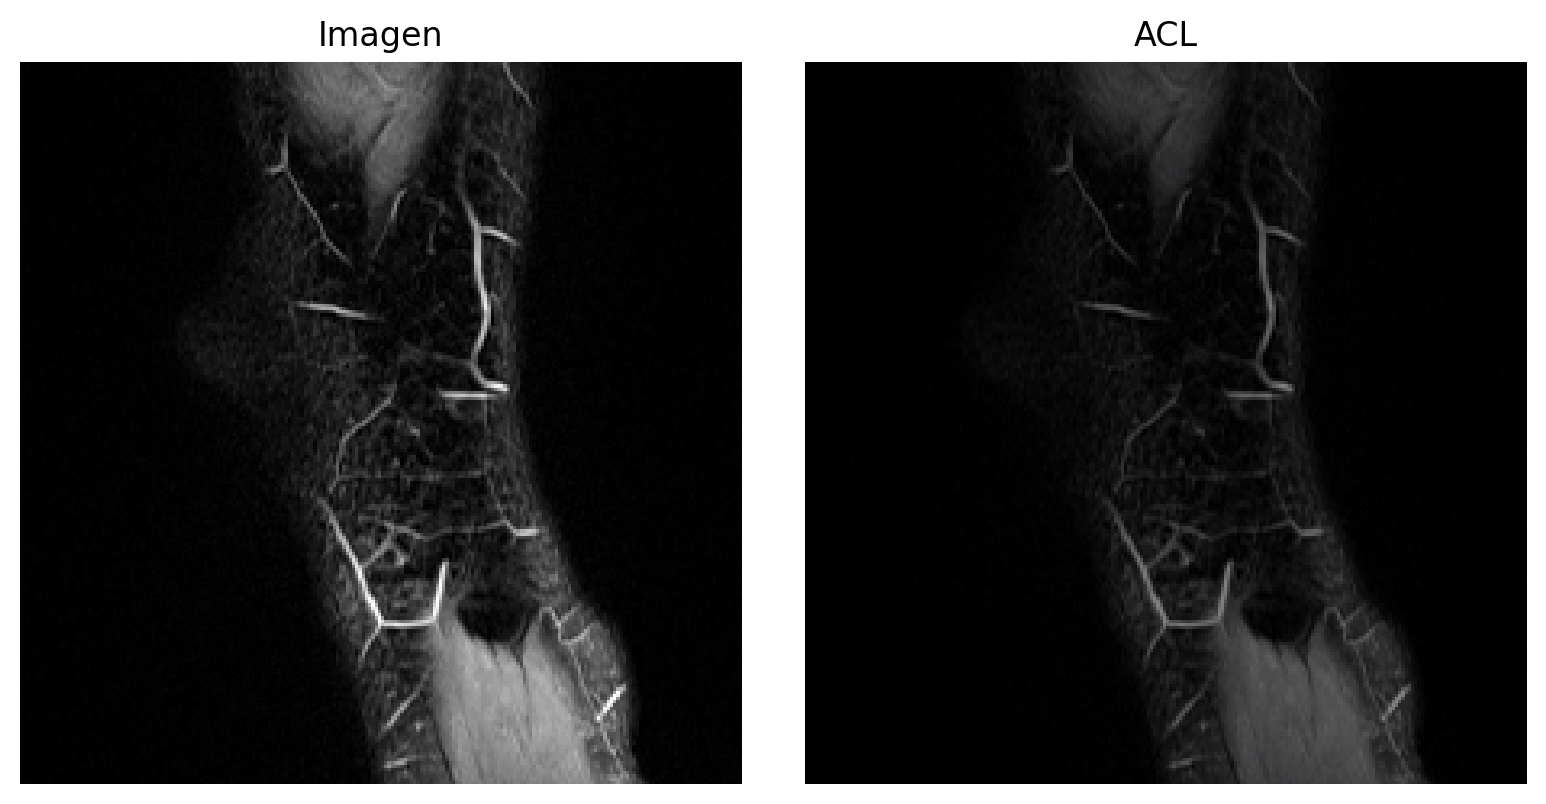

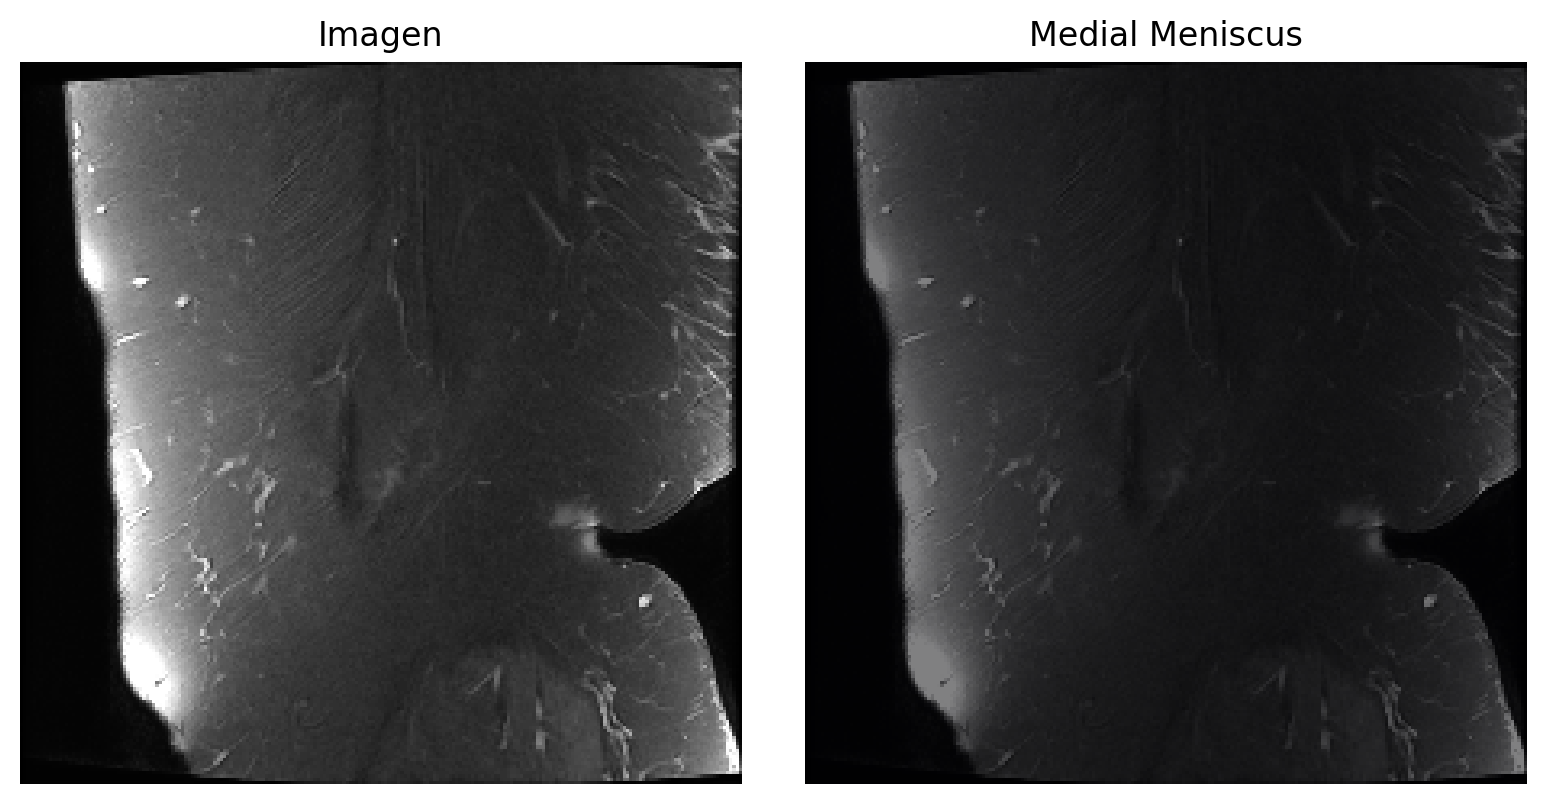

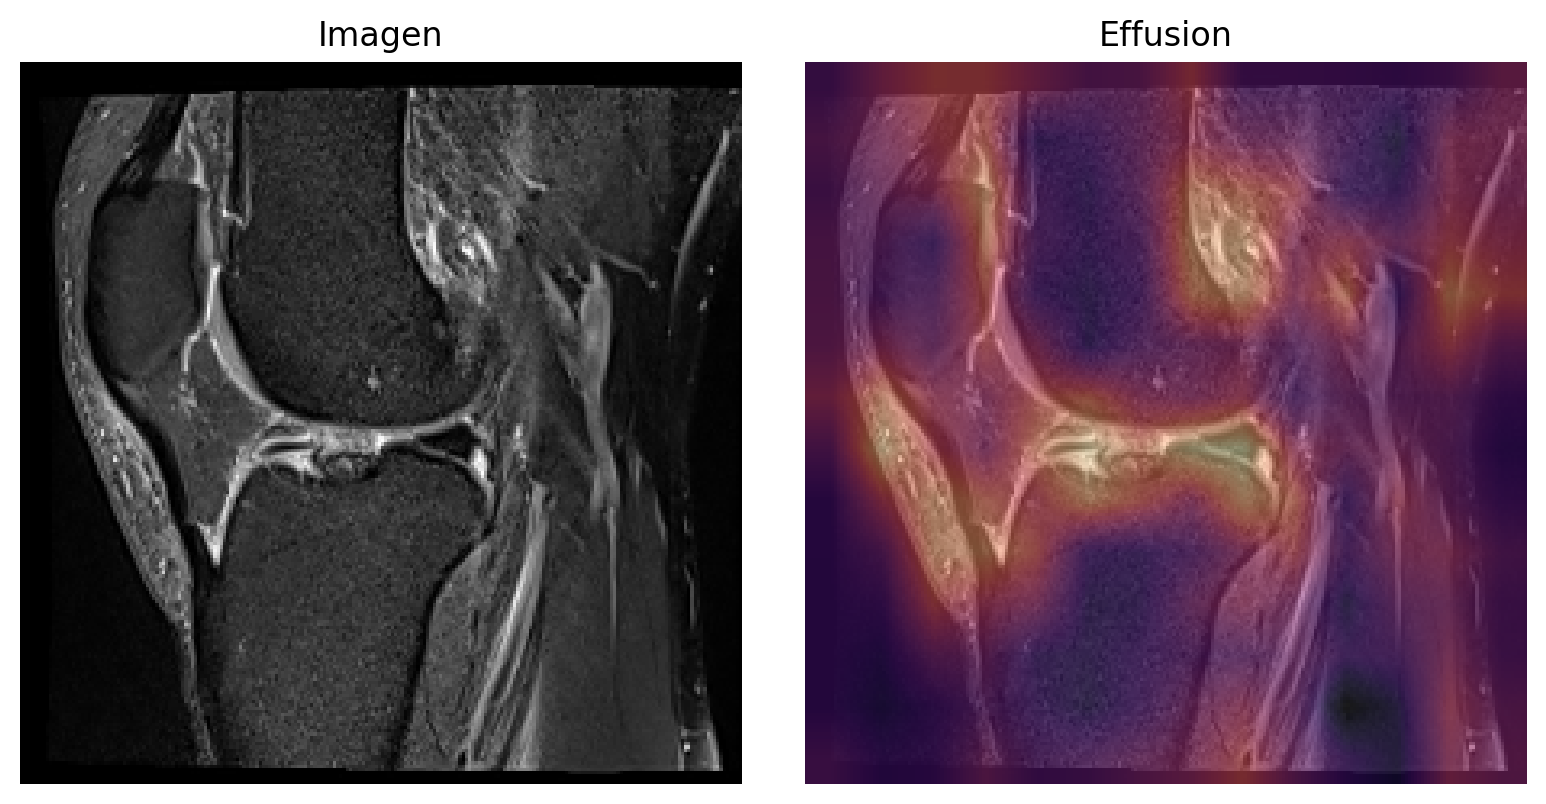

,label,label_index,study_id,series_id,selected_stack,probability,gold_target,selection,nonzero_fraction
0,ACL,0,1.2.826.0.1.3680043.8.498.11382021393803389951...,1.2.826.0.1.3680043.8.498.91903627435354016135...,0,0.364302,1,first gold-positive study; maximum mean normal...,0.00000
1,Medial Meniscus,2,1.2.826.0.1.3680043.8.498.10306159113324811538...,1.2.826.0.1.3680043.8.498.10903465965639594231...,0,0.331387,1,first gold-positive study; maximum mean normal...,0.00000
2,Effusion,7,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.37372672584387115708...,4,0.678923,1,first gold-positive study; maximum mean normal...,0.99998


In [16]:
cam_directory = ACTIVE_ROOT / 'mri/scratch_bce_weighted'
for label_index in (0, 2, 7):
    with np.load(cam_directory / f'cam_{label_index}.npz', allow_pickle=False) as maps:
        assert np.isfinite(maps['heatmaps']).all()
        assert maps['heatmaps'].min() >= 0 and maps['heatmaps'].max() <= 1
    display(Image(filename=str(cam_directory / f'cam_{label_index}.png')))
display(pd.DataFrame(read_json(cam_directory / 'cam_cases.json')))

## 6 Desbalance de clases y mitigación
La pérdida focal pondera clases según prevalencia observada exclusivamente en entrenamiento, después del filtro cuando corresponde. Comparar BCE y focal por precisión, recall y F1: mejorar recall puede reducir precisión. El filtro de sinovitis retiene positivos sin negativos explícitos, lo que limita el aprendizaje.

In [17]:
prevalence_rows = []
for split in ('train', 'val', 'gold'):
    records = [r for r in active_manifest['records'] if r['split'] == split]
    for index, label in enumerate(LABELS):
        observed = sum(r['targets'][index] is not None for r in records)
        positive = sum(r['targets'][index] == 1 for r in records)
        prevalence_rows.append({'split': split, 'label': label, 'positive': positive,
                                'observed': observed,
                                'prevalence': positive / observed if observed else None})
prevalence_table = pd.DataFrame(prevalence_rows)
display(prevalence_table)
imbalance_comparison = evaluation_table.copy()
imbalance_comparison['architecture'] = imbalance_comparison.experiment.str.split('_').str[0]
imbalance_comparison['loss'] = imbalance_comparison.experiment.str.split('_').str[1]
weighted = imbalance_comparison[imbalance_comparison.experiment.str.endswith('_weighted')]
display(weighted.pivot(index=['architecture', 'label'], columns='loss', values=['precision', 'recall', 'f1']))

,split,label,positive,observed,prevalence
0,train,ACL,0,8,0.000000
1,train,MCL,0,8,0.000000
2,train,Medial Meniscus,0,8,0.000000
3,train,Lateral Meniscus,4,8,0.500000
4,train,Medial OA,0,8,0.000000
5,train,Lateral OA,8,8,1.000000
6,train,PF OA,3,8,0.375000
7,train,Effusion,3,8,0.375000
8,train,Synovitis,3,8,0.375000
9,train,Baker's,2,8,0.250000


precision              recall            \
loss                                bce     focal       bce     focal   
architecture label                                                      
resnet50     ACL               0.000000  0.214286  0.000000  0.125000   
             Baker's           0.229167  0.206897  0.916667  1.000000   
             Contusion         0.422222  0.327586  1.000000  1.000000   
             Effusion          0.595745  0.603448  0.800000  1.000000   
             Fracture          0.000000  0.000000  0.000000  0.000000   
             Lateral Meniscus  0.381818  0.385965  0.913043  0.956522   
             Lateral OA        0.189655  0.192982  1.000000  1.000000   
             MCL               0.222222  0.185185  0.222222  0.555556   
             Medial Meniscus   0.000000  1.000000  0.000000  0.038462   
             Medial OA         0.000000  0.500000  0.000000  0.066667   
             PF OA             0.000000  0.372093  0.000000  0.761905   
             Synovitis         0.437500  0.444444  0.777778  0.888889   
scratch      ACL               0.000000  0.000000  0.000000  0.000000   
             Baker's           0.000000  0.206897  0.000000  1.000000   
             Contusion         0.327586  0.327586  1.000000  1.000000   
             Effusion          0.603448  0.603448  1.000000  1.000000   
             Fracture          0.000000  0.000000  0.000000  0.000000   
             Lateral Meniscus  0.396552  0.396552  1.000000  1.000000   
             Lateral OA        0.189655  0.189655  1.000000  1.000000   
             MCL               0.000000  0.000000  0.000000  0.000000   
             Medial Meniscus   0.000000  0.448276  0.000000  1.000000   
             Medial OA         0.000000  0.000000  0.000000  0.000000   
             PF OA             0.362069  0.362069  1.000000  1.000000   
             Synovitis         0.000000  0.465517  0.000000  1.000000   

                                     f1            
loss                                bce     focal  
architecture label                                 
resnet50     ACL               0.000000  0.157895  
             Baker's           0.366667  0.342857  
             Contusion         0.593750  0.493506  
             Effusion          0.682927  0.752688  
             Fracture          0.000000  0.000000  
             Lateral Meniscus  0.538462  0.550000  
             Lateral OA        0.318841  0.323529  
             MCL               0.222222  0.277778  
             Medial Meniscus   0.000000  0.074074  
             Medial OA         0.000000  0.117647  
             PF OA             0.000000  0.500000  
             Synovitis         0.560000  0.592593  
scratch      ACL               0.000000  0.000000  
             Baker's           0.000000  0.342857  
             Contusion         0.493506  0.493506  
             Effusion          0.752688  0.752688  
             Fracture          0.000000  0.000000  
             Lateral Meniscus  0.567901  0.567901  
             Lateral OA        0.318841  0.318841  
             MCL               0.000000  0.000000  
             Medial Meniscus   0.000000  0.619048  
             Medial OA         0.000000  0.000000  
             PF OA             0.531646  0.531646  
             Synovitis         0.000000  0.635294

## 7 Sesgo geográfico y lingüístico
Los reportes proceden de múltiples centros e idiomas según el enunciado. Un léxico puede reconocer mejor ciertas formulaciones y omitir negaciones o expresiones menos representadas. Esto introduce diferencias sistemáticas en las etiquetas de entrenamiento y puede producir errores de clasificación desiguales entre grupos.

Los grupos de escritura Latin/mixed, Greek y Cyrillic no equivalen a idiomas ni a centros. Sin metadatos fiables de procedencia no se puede cuantificar una brecha geográfica. La cobertura textual debe interpretarse como una auditoría limitada del extractor. También existe selección de reportes compatibles con el léxico, por lo que la muestra no representa necesariamente la población completa.

Un despliegue clínico requeriría validación local independiente, revisión de etiquetas por especialistas, evaluación por idioma y centro y análisis de falsos negativos. Los 58 estudios expertos y una sola semilla limitan las conclusiones; los mapas no sustituyen validación radiológica. Los expertos se reutilizaron tras una corrección de partición basada únicamente en etiquetas débiles. Se mantienen estas limitaciones al interpretar los ocho experimentos históricos.